In [1]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [2]:
X_train = pd.read_csv("../data/selected/X_train_selected.csv")
X_val = pd.read_csv("../data/selected/X_val_selected.csv")
X_test = pd.read_csv("../data/selected/X_test_selected.csv")
y_train = pd.read_csv("../data/selected/y_train.csv").squeeze()
y_val = pd.read_csv("../data/selected/y_val.csv").squeeze()
y_test = pd.read_csv("../data/selected/y_test.csv").squeeze()
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (13984, 15)
Validation: (2997, 15)
Test: (2997, 15)


In [3]:
logistic_param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear", "lbfgs"],
    "class_weight": [None, "balanced"]
}
logistic_grid = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=42),
    param_grid=logistic_param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)
logistic_grid.fit(X_train, y_train)
print("Best parameters:")
print(logistic_grid.best_params_)
print("\nBest cross-validation F1:")
print(round(logistic_grid.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters:
{'C': 0.1, 'class_weight': None, 'solver': 'liblinear'}

Best cross-validation F1:
0.9074


In [4]:
best_logistic = logistic_grid.best_estimator_
y_val_pred = best_logistic.predict(X_val)
accuracy = accuracy_score(y_val, y_val_pred)
precision = precision_score(y_val, y_val_pred)
recall = recall_score(y_val, y_val_pred)
f1 = f1_score(y_val, y_val_pred)
print("Optimized Logistic Regression - Validation Results")
print("-----------------------------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

Optimized Logistic Regression - Validation Results
-----------------------------------------------
Accuracy : 0.8428
Precision: 0.8699
Recall   : 0.9433
F1 Score : 0.9051


In [5]:
joblib.dump(
    best_logistic,
    "../models/logistic_regression_optimized.pkl"
)
print("Optimized Logistic Regression saved successfully.")

Optimized Logistic Regression saved successfully.


In [6]:
dt_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "class_weight": [None, "balanced"]
}
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)
dt_grid.fit(X_train, y_train)
print("Best parameters:")
print(dt_grid.best_params_)
print("\nBest cross-validation F1:")
print(round(dt_grid.best_score_, 4))

Fitting 5 folds for each of 180 candidates, totalling 900 fits
Best parameters:
{'class_weight': None, 'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10}

Best cross-validation F1:
0.9261


In [7]:
best_dt = dt_grid.best_estimator_
y_val_pred_dt = best_dt.predict(X_val)
accuracy_dt = accuracy_score(y_val, y_val_pred_dt)
precision_dt = precision_score(y_val, y_val_pred_dt)
recall_dt = recall_score(y_val, y_val_pred_dt)
f1_dt = f1_score(y_val, y_val_pred_dt)
print("Optimized Decision Tree - Validation Results")
print("---------------------------------------------")
print("Accuracy :", round(accuracy_dt, 4))
print("Precision:", round(precision_dt, 4))
print("Recall   :", round(recall_dt, 4))
print("F1 Score :", round(f1_dt, 4))

Optimized Decision Tree - Validation Results
---------------------------------------------
Accuracy : 0.8792
Precision: 0.9105
Recall   : 0.9404
F1 Score : 0.9252


In [8]:
joblib.dump(
    best_dt,
    "../models/decision_tree_optimized.pkl"
)
print("Optimized Decision Tree saved successfully.")

Optimized Decision Tree saved successfully.


In [11]:
rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"],
    "class_weight": [None, "balanced"]
}
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=rf_param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)
rf_grid.fit(X_train, y_train)
print("Best parameters:")
print(rf_grid.best_params_)
print("\nBest cross-validation F1:")
print(round(rf_grid.best_score_, 4))

Fitting 5 folds for each of 144 candidates, totalling 720 fits
Best parameters:
{'class_weight': None, 'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}

Best cross-validation F1:
0.9366


In [12]:
best_rf = rf_grid.best_estimator_
y_val_pred_rf = best_rf.predict(X_val)
accuracy_rf = accuracy_score(y_val, y_val_pred_rf)
precision_rf = precision_score(y_val, y_val_pred_rf)
recall_rf = recall_score(y_val, y_val_pred_rf)
f1_rf = f1_score(y_val, y_val_pred_rf)
print("Optimized Random Forest - Validation Results")
print("--------------------------------------------")
print("Accuracy :", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall   :", round(recall_rf, 4))
print("F1 Score :", round(f1_rf, 4))

Optimized Random Forest - Validation Results
--------------------------------------------
Accuracy : 0.8902
Precision: 0.9127
Recall   : 0.953
F1 Score : 0.9324


In [13]:
joblib.dump(
    best_rf,
    "../models/random_forest_optimized.pkl"
)
print("Optimized Random Forest saved successfully.")

Optimized Random Forest saved successfully.


In [14]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        accuracy_dt,
        accuracy_rf
    ],
    "Precision": [
        precision,
        precision_dt,
        precision_rf
    ],
    "Recall": [
        recall,
        recall_dt,
        recall_rf
    ],
    "F1 Score": [
        f1,
        f1_dt,
        f1_rf
    ]
})
comparison = comparison.round(4)
print(comparison.to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression    0.8428     0.8699  0.9433    0.9051
      Decision Tree    0.8792     0.9105  0.9404    0.9252
      Random Forest    0.8902     0.9127  0.9530    0.9324


In [15]:
models = {
    "Logistic Regression": best_logistic,
    "Decision Tree": best_dt,
    "Random Forest": best_rf
}
test_results = []
for name, model in models.items():
    y_pred = model.predict(X_test)

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })
test_comparison = pd.DataFrame(test_results).round(4)
print("FINAL TEST RESULTS")
print("==================")
print(test_comparison.to_string(index=False))

FINAL TEST RESULTS
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression    0.8555     0.8718  0.9593    0.9134
      Decision Tree    0.8946     0.9165  0.9542    0.9350
      Random Forest    0.9096     0.9217  0.9685    0.9445


In [16]:
test_comparison.to_csv(
    "../results/metrics/final_test_results.csv",
    index=False
)
comparison.to_csv(
    "../results/metrics/validation_model_comparison.csv",
    index=False
)
print("Final test results saved.")
print("Validation comparison saved.")

Final test results saved.
Validation comparison saved.


Confusion Matrix:
[[ 420  196]
 [  75 2306]]


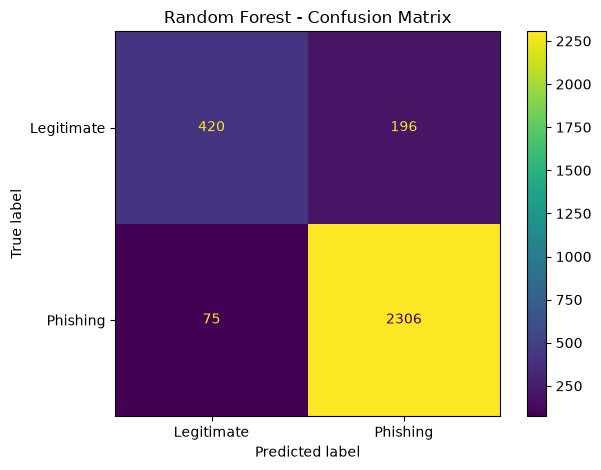

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
y_test_pred_rf = best_rf.predict(X_test)
cm = confusion_matrix(y_test, y_test_pred_rf)
print("Confusion Matrix:")
print(cm)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Phishing"]
)
disp.plot()
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "../results/figures/random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Random Forest ROC-AUC: 0.9494


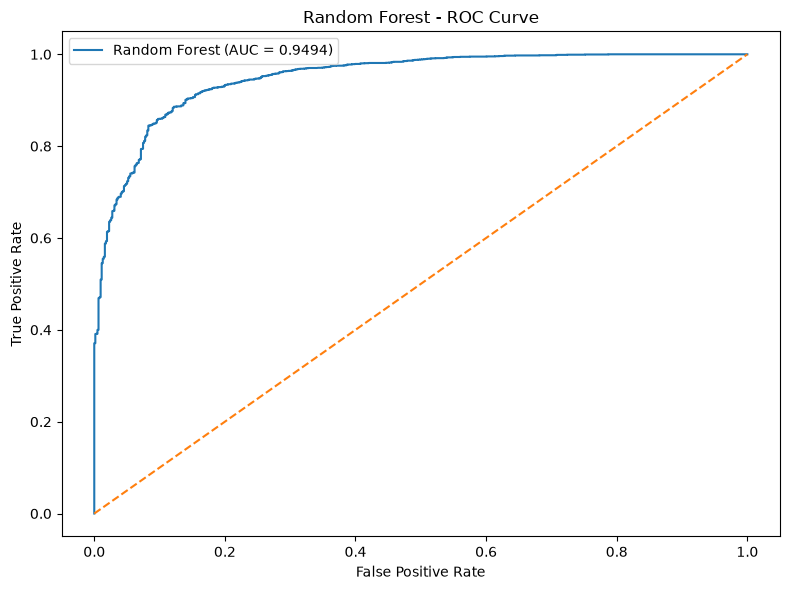

In [18]:
from sklearn.metrics import roc_curve, roc_auc_score
y_test_proba_rf = best_rf.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba_rf)
auc_score = roc_auc_score(y_test, y_test_proba_rf)
print("Random Forest ROC-AUC:", round(auc_score, 4))
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest - ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig(
    "../results/figures/random_forest_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Random Forest Average Precision: 0.9856


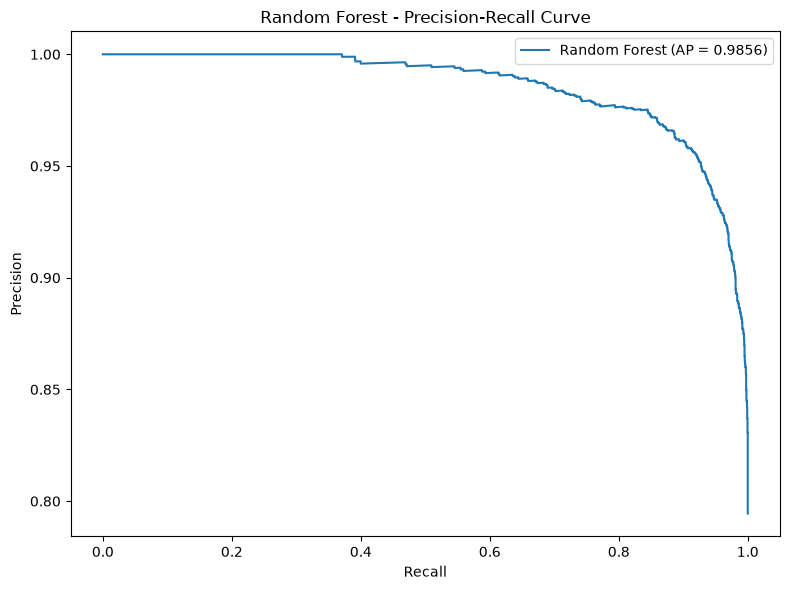

In [19]:
from sklearn.metrics import precision_recall_curve, average_precision_score
precision_curve, recall_curve, pr_thresholds = precision_recall_curve(
    y_test,
    y_test_proba_rf
)
ap_score = average_precision_score(
    y_test,
    y_test_proba_rf
)
print("Random Forest Average Precision:", round(ap_score, 4))
plt.figure(figsize=(8, 6))
plt.plot(
    recall_curve,
    precision_curve,
    label=f"Random Forest (AP = {ap_score:.4f})"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest - Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.savefig(
    "../results/figures/random_forest_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

       Feature  Importance
    url_length    0.262728
       n_slash    0.207407
      n_hypens    0.149415
        n_dots    0.096096
         count    0.078671
 n_redirection    0.073715
       n_equal    0.043732
     n_percent    0.024983
         n_and    0.018476
n_questionmark    0.016953
          n_at    0.015336
        n_plus    0.006631
       n_space    0.004820
    n_asterisk    0.000812
      n_dollar    0.000226


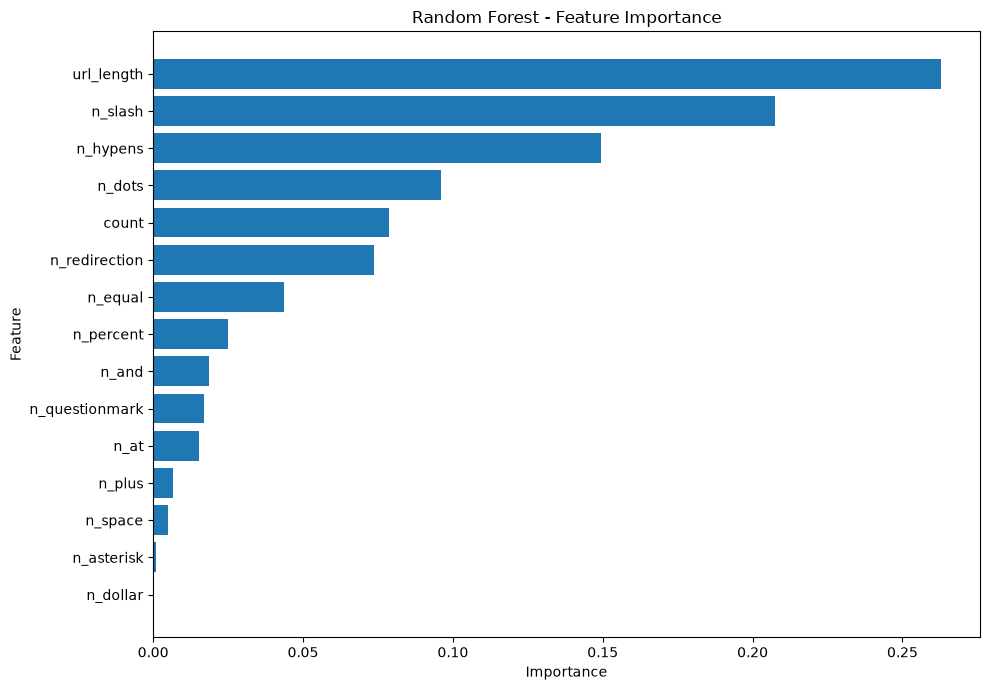

In [20]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf.feature_importances_
})
feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)
print(feature_importance.to_string(index=False))
plt.figure(figsize=(10, 7))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest - Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    "../results/figures/random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()